In [2]:
import pandas as pd
import requests
import zipfile
import io

url = "https://archive.ics.uci.edu/static/public/350/default+of+credit+card+clients.zip"

response = requests.get(url, timeout=30)
response.raise_for_status()

with zipfile.ZipFile(io.BytesIO(response.content)) as archive:
    print(archive.namelist())

['default of credit card clients.xls']


In [3]:
with zipfile.ZipFile(io.BytesIO(response.content)) as archive:
    with archive.open("default of credit card clients.xls") as file:
        df = pd.read_excel(file, header=1)

print(df.shape)
df.head()

C:\Users\Simrat Khalsa\AppData\Local\Temp\ipykernel_10040\1233381312.py:3: Pandas4Warning: The xlrd engine is deprecated and will be removed in a future version. Use the calamine engine instead, by setting engine='calamine'.
  df = pd.read_excel(file, header=1)


(30000, 25)


,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default payment next month
0,1,20000,2,2,1,24,2,2,-1,-1,...,0,0,0,0,689,0,0,0,0,1
1,2,120000,2,2,2,26,-1,2,0,0,...,3272,3455,3261,0,1000,1000,1000,0,2000,1
2,3,90000,2,2,2,34,0,0,0,0,...,14331,14948,15549,1518,1500,1000,1000,1000,5000,0
3,4,50000,2,2,1,37,0,0,0,0,...,28314,28959,29547,2000,2019,1200,1100,1069,1000,0
4,5,50000,1,2,1,57,-1,0,-1,0,...,20940,19146,19131,2000,36681,10000,9000,689,679,0


In [10]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 30000 entries, 0 to 29999
Data columns (total 25 columns):
 #   Column                      Non-Null Count  Dtype
---  ------                      --------------  -----
 0   ID                          30000 non-null  int64
 1   LIMIT_BAL                   30000 non-null  int64
 2   SEX                         30000 non-null  int64
 3   EDUCATION                   30000 non-null  int64
 4   MARRIAGE                    30000 non-null  int64
 5   AGE                         30000 non-null  int64
 6   PAY_0                       30000 non-null  int64
 7   PAY_2                       30000 non-null  int64
 8   PAY_3                       30000 non-null  int64
 9   PAY_4                       30000 non-null  int64
 10  PAY_5                       30000 non-null  int64
 11  PAY_6                       30000 non-null  int64
 12  BILL_AMT1                   30000 non-null  int64
 13  BILL_AMT2                   30000 non-null  int64
 14  BILL_AMT3        

In [9]:
default_rate = df['default payment next month'].mean() * 100
default_rate

np.float64(22.12)

In [ ]:
df.isna().sum()
# No missing values in the dataset

ID                            0
LIMIT_BAL                     0
SEX                           0
EDUCATION                     0
MARRIAGE                      0
AGE                           0
PAY_0                         0
PAY_2                         0
PAY_3                         0
PAY_4                         0
PAY_5                         0
PAY_6                         0
BILL_AMT1                     0
BILL_AMT2                     0
BILL_AMT3                     0
BILL_AMT4                     0
BILL_AMT5                     0
BILL_AMT6                     0
PAY_AMT1                      0
PAY_AMT2                      0
PAY_AMT3                      0
PAY_AMT4                      0
PAY_AMT5                      0
PAY_AMT6                      0
default payment next month    0
dtype: int64

In [10]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
ID,30000.0,15000.500000,8660.398374,1.0,7500.75,15000.5,22500.25,30000.0
LIMIT_BAL,30000.0,167484.322667,129747.661567,10000.0,50000.00,140000.0,240000.00,1000000.0
SEX,30000.0,1.603733,0.489129,1.0,1.00,2.0,2.00,2.0
EDUCATION,30000.0,1.853133,0.790349,0.0,1.00,2.0,2.00,6.0
MARRIAGE,30000.0,1.551867,0.521970,0.0,1.00,2.0,2.00,3.0
AGE,30000.0,35.485500,9.217904,21.0,28.00,34.0,41.00,79.0
PAY_0,30000.0,-0.016700,1.123802,-2.0,-1.00,0.0,0.00,8.0
PAY_2,30000.0,-0.133767,1.197186,-2.0,-1.00,0.0,0.00,8.0
PAY_3,30000.0,-0.166200,1.196868,-2.0,-1.00,0.0,0.00,8.0
PAY_4,30000.0,-0.220667,1.169139,-2.0,-1.00,0.0,0.00,8.0


In [11]:
df["EDUCATION"].value_counts()

EDUCATION
2    14030
1    10585
3     4917
5      280
4      123
6       51
0       14
Name: count, dtype: int64

In [12]:
df["MARRIAGE"].value_counts()

MARRIAGE
2    15964
1    13659
3      323
0       54
Name: count, dtype: int64

In [13]:
df["SEX"].value_counts()

SEX
2    18112
1    11888
Name: count, dtype: int64

In [23]:
# Group by credit limit and default payment
average_credit_limit_by_default = df.groupby('default payment next month')['LIMIT_BAL'].mean().reset_index()
average_credit_limit_by_default

,default payment next month,LIMIT_BAL
0,0,178099.726074
1,1,130109.656420


In [24]:
# Median credit limit for both groups
median_credit_limit_by_default = df.groupby('default payment next month')['LIMIT_BAL'].median().reset_index()
median_credit_limit_by_default

,default payment next month,LIMIT_BAL
0,0,150000.0
1,1,90000.0


In [26]:
# Aggregate credit limit statistics for both groups
credit_limit_stats = df.groupby('default payment next month')['LIMIT_BAL'].agg(['mean', 'median', 'std']).reset_index()
credit_limit_stats

,default payment next month,mean,median,std
0,0,178099.726074,150000.0,131628.359660
1,1,130109.656420,90000.0,115378.540571


In [27]:
df.groupby('default payment next month')['LIMIT_BAL'].skew()

default payment next month
0    0.912454
1    1.351724
Name: LIMIT_BAL, dtype: float64

In [40]:
bins = [0, 50000, 100000, 200000, 300000, float('inf')]

labels = [
    'Very Low',
    'Low',
    'Medium',
    'High',
    'Very High'
]
credit_limit_group = pd.cut(df['LIMIT_BAL'], bins=bins, labels=labels, right=False)

# Group dataset by new column
df_grouped = df.groupby(credit_limit_group).value_counts()

# Calculate default rate per group
default_rates = df.groupby(credit_limit_group)['default payment next month'].mean() * 100

frames = [df_grouped, default_rates]

df_rate = pd.concat(frames, axis=1)

df_rate





NotImplementedError: Can only union MultiIndex with MultiIndex or Index of tuples, try mi.to_flat_index().union(other) instead.

Matplotlib is building the font cache; this may take a moment.


<Axes: xlabel='LIMIT_BAL'>

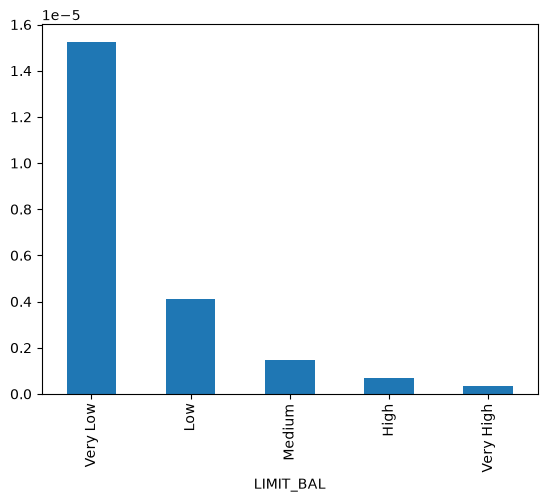

In [31]:
# Plot default rates using bar chart
default_rates.plot(kind='bar')